# Reading **Netgen** volume meshes with `pyramids-mesh`

Netgen is the open-source mesh generator behind *NGSolve*; its `.vol` format records points, surface elements and volume elements for finite-element analysis. `pyramids-mesh` provides a **driver** that parses the `.vol` file into a `pyramids.netcdf.ugrid.UgridDataset` and nothing more — the mesh operations all belong upstream in `pyramids`.

Our sample is `netgen/periodic_3d.vol` (meshio test data, MIT; NETGEN v6.2): a periodic 3-D test mesh — **65 points and 108 triangular surface elements**. It is **geometry only, `crs=None`**.

## 1. Pin a non-interactive plotting backend

Every figure in this tutorial is rendered by `matplotlib` (the engine behind `cleopatra`, the plotting layer `pyramids` reaches). So the notebook produces the *same* output in headless CI as it does interactively, we select the non-interactive `Agg` backend **before** importing `pyplot`. The small `show()` helper then rasterises the current figure straight into the notebook — under `Agg` a bare plot call draws nothing visible on its own, so we call `show()` after every plot.

In [1]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display


def show():
    """Rasterise the current figure and embed it in the notebook."""
    from io import BytesIO
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all")
    buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np

## 3. Locate the sample file

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths are written **relative to the notebook itself**. We will read the Netgen mesh `netgen/periodic_3d.vol`.

> **Pass a `pathlib.Path`, never a string.** `read_file` keys its driver dispatch off `Path` objects; a bare `str` is not accepted.

In [3]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "netgen" / "periodic_3d.vol"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/netgen/periodic_3d.vol'), True)

## 4. Read it in one line

The `.vol` file is a keyword-blocked ASCII dump (`surfaceelements`, `points`, ...). We name the driver explicitly with `driver="netgen"` and hand `read_file` the `Path`. What comes back is a `UgridDataset` — the same mesh container every other `pyramids` mesh uses.

In [4]:
ds = UgridDataset.read_file(mesh_file, driver="netgen")
type(ds).__name__

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 20 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 72 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


'UgridDataset'

## 5. Inspect the dataset

A handful of attributes describe the mesh at a glance: the node and face counts, the coordinate reference system, the list of data variables, and the planar bounding box `(xmin, ymin, xmax, ymax)`. Netgen meshes are defined in abstract geometry units, so `crs` and `epsg` are `None`.

In [5]:
print("nodes        :", ds.n_node)
print("faces        :", ds.n_face)
print("crs          :", ds.crs)
print("epsg         :", ds.epsg)
print("data variables:", ds.data_variable_names)
print("bounds       :", ds.bounds)

nodes        : 65
faces        : 108
crs          : None
epsg         : None
data variables: ['node_z']
bounds       : (0.0, 0.0, 1.0, 1.0)


### A statistical summary of the data variables

`ds.summary()` returns a small `pandas` table — one row per data variable with count, min, max, mean and std. The mesh exposes a `node_z` variable (the vertices' third coordinate), so the summary has one row describing it.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,65,0.0,1.0,0.462335,0.372546


## 6. The underlying geometry

`ds.mesh` is a `Mesh2d`. Its node coordinates live in `node_x` / `node_y`, and its face-to-node table is `face_node_connectivity.data` — an `(n_face, k)` integer array where row *i* lists the node indices of face *i*. Three node indices per row confirms a triangular surface mesh. A winding-normalisation warning on read is expected and harmless.

In [7]:
m = ds.mesh
fnc = m.face_node_connectivity.data
print("node_x range :", float(np.min(m.node_x)), "->", float(np.max(m.node_x)))
print("node_y range :", float(np.min(m.node_y)), "->", float(np.max(m.node_y)))
print("connectivity :", fnc.shape, "(n_face, nodes-per-face)")
fnc[:3]

node_x range : 0.0 -> 1.0
node_y range : 0.0 -> 1.0
connectivity : (108, 3) (n_face, nodes-per-face)


array([[31,  8,  0],
       [32,  9,  8],
       [ 9, 33,  3]])

## 7. Draw the mesh outline (wireframe)

`plot_outline()` draws the cell edges with no fill — the quickest way to *see* the topology we just read. Remember to follow every plot with `show()` so the figure is embedded.

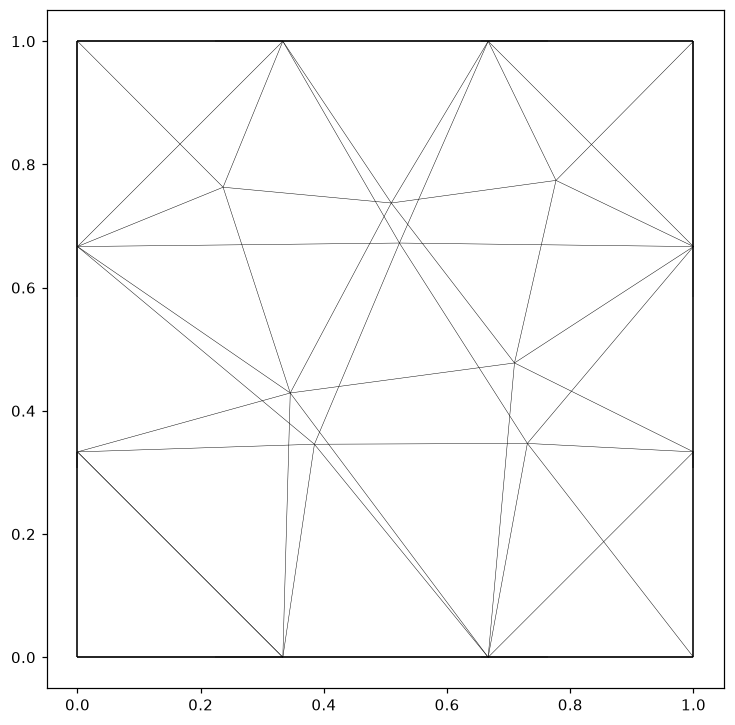

In [8]:
ds.plot_outline()
show()

## 8. A filled map: projected cell area

These are engineering meshes with **no CRS and (usually) no field data**, so there is nothing physical to colour by out of the box. A useful derived quantity is the **projected 2-D area of each cell**, available as `mesh.face_areas`. We attach it as a face variable with `with_variable(...)` and let `plot(...)` draw a filled colour map.

This triangulation has genuinely non-zero projected areas across most cells, so the colour map varies smoothly — a good sanity check that the geometry parsed correctly.

area  min/max: 0.0 0.08614955958778252


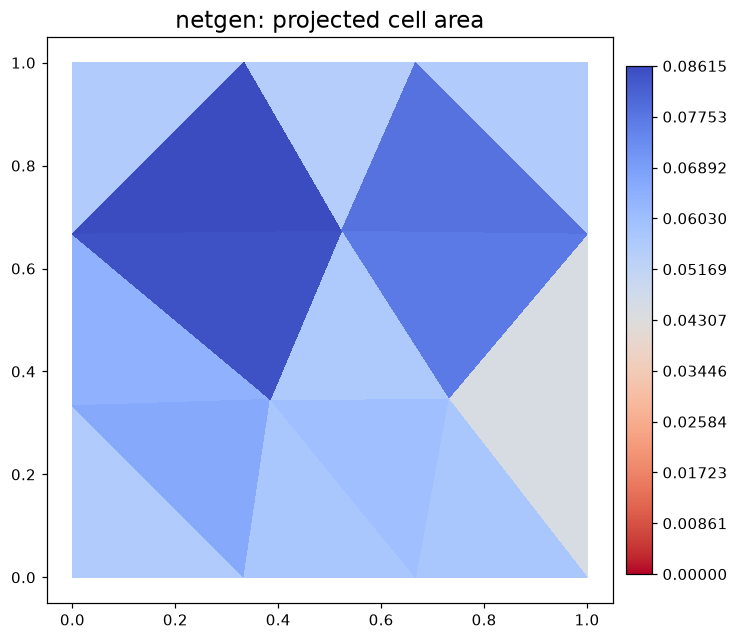

In [9]:
areas = np.asarray(ds.mesh.face_areas)
print("area  min/max:", float(areas.min()), float(areas.max()))
ds_area = ds.with_variable("cell_area", areas, location="face")
ds_area.plot("cell_area", cmap="viridis", colorbar=True,
             title="netgen: projected cell area")
show()

## 9. The pyramids GIS toolbox applies

The payoff of turning a solver file into a `pyramids` object is that the whole GIS toolbox now works on it, even though this is a FEM/CFD mesh. Below we exercise several operations and interpret each result.

### Export to a GeoDataFrame

`to_geodataframe()` turns every cell into a `shapely` polygon inside a `geopandas` `GeoDataFrame` — the bridge to the entire vector-GIS ecosystem. Because the mesh has `crs=None`, the frame is unprojected (model units, not metres/degrees).

In [10]:
gdf = ds.to_geodataframe()
print("rows:", len(gdf), "| columns:", list(gdf.columns))
gdf.head()

rows: 108 | columns: ['geometry']


,geometry
0,"POLYGON ((0.33333 0, 0 0.33333, 0 0, 0.33333 0))"
1,"POLYGON ((0.34538 0.42896, 0 0.66667, 0 0.3333..."
2,"POLYGON ((0 0.66667, 0.23637 0.763, 0 1, 0 0.6..."
3,"POLYGON ((0.34538 0.42896, 0.23637 0.763, 0 0...."
4,"POLYGON ((0.23637 0.763, 0.33333 1, 0 1, 0.236..."


`geopandas` can draw it directly. This is the same geometry as the wireframe, now as first-class vector features.

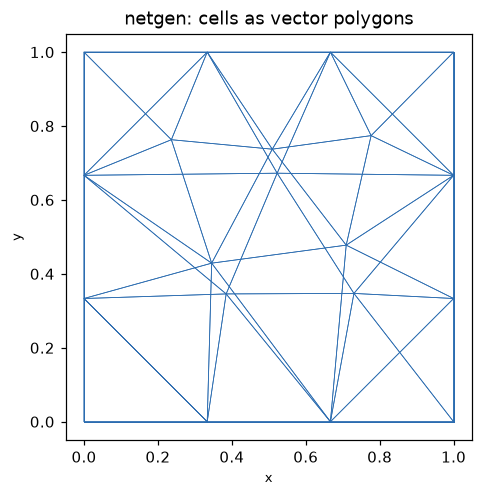

In [11]:
ax = gdf.plot(facecolor="none", edgecolor="#2b6cb0", linewidth=0.5)
ax.set_title("netgen: cells as vector polygons")
ax.set_aspect("equal")
show()

### Dissolve to a bounding polygon

`bounding_polygon()` unions all cells into the single outer footprint of the mesh — useful as a clip mask or domain outline. We overlay it (red) on the grey cell edges.

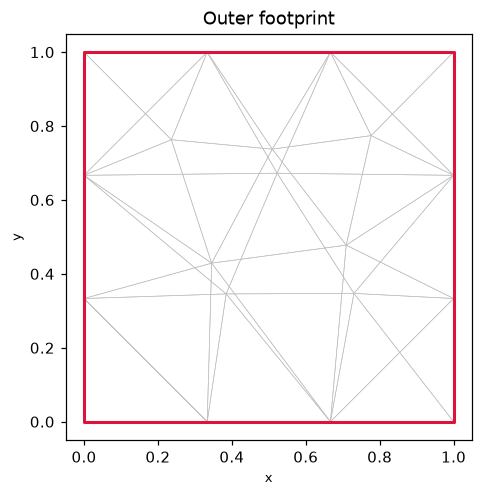

In [12]:
poly = ds.bounding_polygon()
ax = gdf.plot(facecolor="none", edgecolor="0.75", linewidth=0.4)
xs, ys = poly.exterior.xy
ax.plot(xs, ys, color="crimson", linewidth=2)
ax.set_aspect("equal")
ax.set_title("Outer footprint")
show()

### Triangle circumcenters

`circumcenters()` returns the `(n_face, 2)` circumcentre of each **triangular** cell — the dual-mesh vertices that finite-volume schemes use. (It is defined only for triangle meshes; the quad/polyhedral notebooks skip it.)

circumcenters: (108, 2)


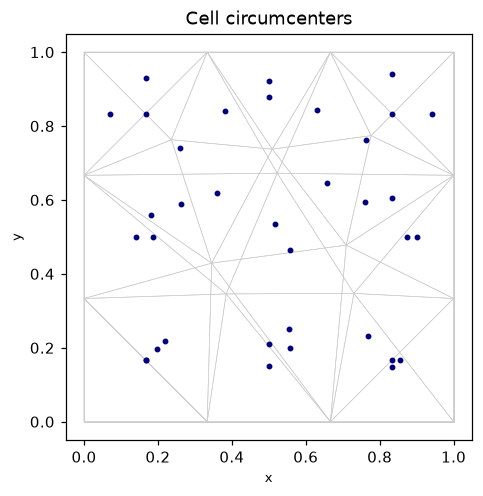

In [13]:
cen = np.asarray(ds.circumcenters())
print("circumcenters:", cen.shape)
ax = gdf.plot(facecolor="none", edgecolor="0.8", linewidth=0.4)
ax.scatter(cen[:, 0], cen[:, 1], s=8, color="navy")
ax.set_aspect("equal")
ax.set_title("Cell circumcenters")
show()

### Face-adjacency as a sparse matrix

`sparse_adjacency()` returns the `(n_face, n_face)` SciPy CSR matrix of which cells share an edge — the connectivity graph solvers assemble their stencils from. We only report its shape and non-zero count.

In [14]:
A = ds.sparse_adjacency()
print("adjacency:", A.shape, "| non-zeros (directed edges):", A.nnz)

adjacency: (108, 108) | non-zeros (directed edges): 324


### Crop to a sub-region

`crop(bbox=(xmin, ymin, xmax, ymax))` keeps only the cells inside a window — the mesh equivalent of a spatial subset. Here we take the left half of the domain and re-draw it.

kept 54 of 108 cells


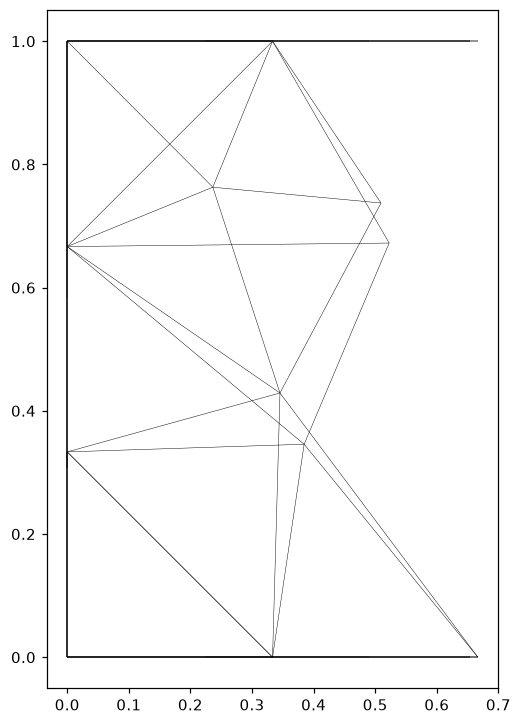

In [15]:
xmin, ymin, xmax, ymax = ds.bounds
sub = ds.crop(bbox=(xmin, ymin, (xmin + xmax) / 2, ymax))
if sub.n_face == 0:
    sub = ds  # degenerate window; fall back to the whole mesh
print("kept", sub.n_face, "of", ds.n_face, "cells")
sub.plot_outline()
show()

### Bridge to xarray

`to_xarray()` exposes the mesh and its variables as an `xarray.Dataset` (UGRID conventions) — the door to NetCDF I/O and the scientific-Python stack.

In [16]:
xds = ds.to_xarray()
print("dimensions:", dict(xds.sizes))
xds

dimensions: {'mesh2d_scalar': 1, 'mesh2d_nNodes': 65, 'mesh2d_nFaces': 108, 'mesh2d_nMaxFaceNodes': 3}


<xarray.Dataset> Size: 4kB
Dimensions:            (mesh2d_scalar: 1, mesh2d_nNodes: 65,
                        mesh2d_nFaces: 108, mesh2d_nMaxFaceNodes: 3)
Dimensions without coordinates: mesh2d_scalar, mesh2d_nNodes, mesh2d_nFaces,
                                mesh2d_nMaxFaceNodes
Data variables:
    mesh2d             (mesh2d_scalar) int32 4B 0
    mesh2d_node_x      (mesh2d_nNodes) float64 520B 0.0 0.0 ... 0.6904 0.2154
    mesh2d_node_y      (mesh2d_nNodes) float64 520B 0.0 0.0 ... 0.5313 0.2182
    mesh2d_face_nodes  (mesh2d_nFaces, mesh2d_nMaxFaceNodes) int64 3kB 32 ... 56
    node_z             (mesh2d_nNodes) float64 520B 0.0 1.0 0.0 ... 0.6779 0.234
Attributes:
    Conventions:  CF-1.8 UGRID-1.0

### What we skip, and why

Because this mesh carries **`crs=None`**, the reprojection and raster-bridge operations do not apply:

- `to_crs(...)` needs a source CRS to reproject *from* — skipped (there is no datum to interpret the model's bare coordinates).
- `rasterize_like(...)` / `regrid(...)` burn a mesh onto, or resample it against, a georeferenced raster grid — skipped here, as there is no spatial reference to align to.

These are first-class `pyramids` operations; they simply require a georeferenced mesh, which an engineering solver file is not.

## Takeaway

We read a Netgen `.vol`, inspected its 65 nodes / 108 triangles, mapped projected cell area, then exercised GIS: vector export, outer footprint, circumcenters, the sparse adjacency graph, a crop, and an xarray bridge.

The pattern is always the same: **`UgridDataset.read_file(path, driver=...)` turns a solver file into a `pyramids` object, and from there the full GIS toolbox applies** — even for a geometry-only, CRS-less engineering mesh. `pyramids-mesh` contributes only the driver; every mesh operation lives upstream in `pyramids`.